# 05 · Portfolio Construction — From Markowitz to Hierarchical Risk Parity

**Question:** Given 10 NIFTY sector indices, Indian government bonds and gold, which allocation
method gives the best risk-adjusted outcome *out of sample*?

Mean-variance optimisation looks brilliant in-sample and disappoints in practice because it treats
noisy estimates of expected returns as truth. We compare six methods in a strict **walk-forward**
setting (estimate on the past 252 days, hold for a month, repeat), net of costs:

| Method | Uses expected returns? | Idea |
|---|---|---|
| Equal weight (1/N) | No | The "naive" benchmark that is famously hard to beat (DeMiguel et al., 2009) |
| Max Sharpe (Markowitz) | **Yes** | Tangency portfolio from sample means & covariance |
| Minimum variance | No | Lowest-risk portfolio, Ledoit-Wolf shrunk covariance |
| Inverse volatility | No | Weight ∝ 1/σ |
| Equal risk contribution | No | Every asset contributes the same share of portfolio risk |
| **Hierarchical Risk Parity** | No | Cluster correlated assets, allocate top-down (López de Prado, 2016) |

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent / "src") if (Path.cwd().parent / "src").exists() else "src")

import numpy as np
import pandas as pd
from scipy.cluster.hierarchy import leaves_list, linkage
from scipy.optimize import minimize
from scipy.spatial.distance import squareform
from sklearn.covariance import LedoitWolf

from nql import data, metrics
from nql.plotting import PALETTE, plt, save

ASSETS = {k: v for k, v in data.SECTORS.items() if k not in ("Fin Serv", "PSU Bank")}
ASSETS.update({"G-Sec 10Y": "nifty 10 yr benchmark g-sec", "Gold": "goldbees"})
px = data.panel(ASSETS.values()).set_axis(list(ASSETS), axis=1).loc["2015-11-09":].ffill().dropna()
ret = px.pct_change().dropna()
rf = data.risk_free_daily(ret.index)
nifty_r = data.nifty().pct_change().reindex(ret.index).fillna(0)
COST, LOOKBACK = 0.0010, 252
print(px.shape, ret.index[0].date(), "→", ret.index[-1].date())

(2693, 12) 2015-11-10 → 2026-09-25


## 1 · Correlation structure (why diversification across sectors alone is limited)

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


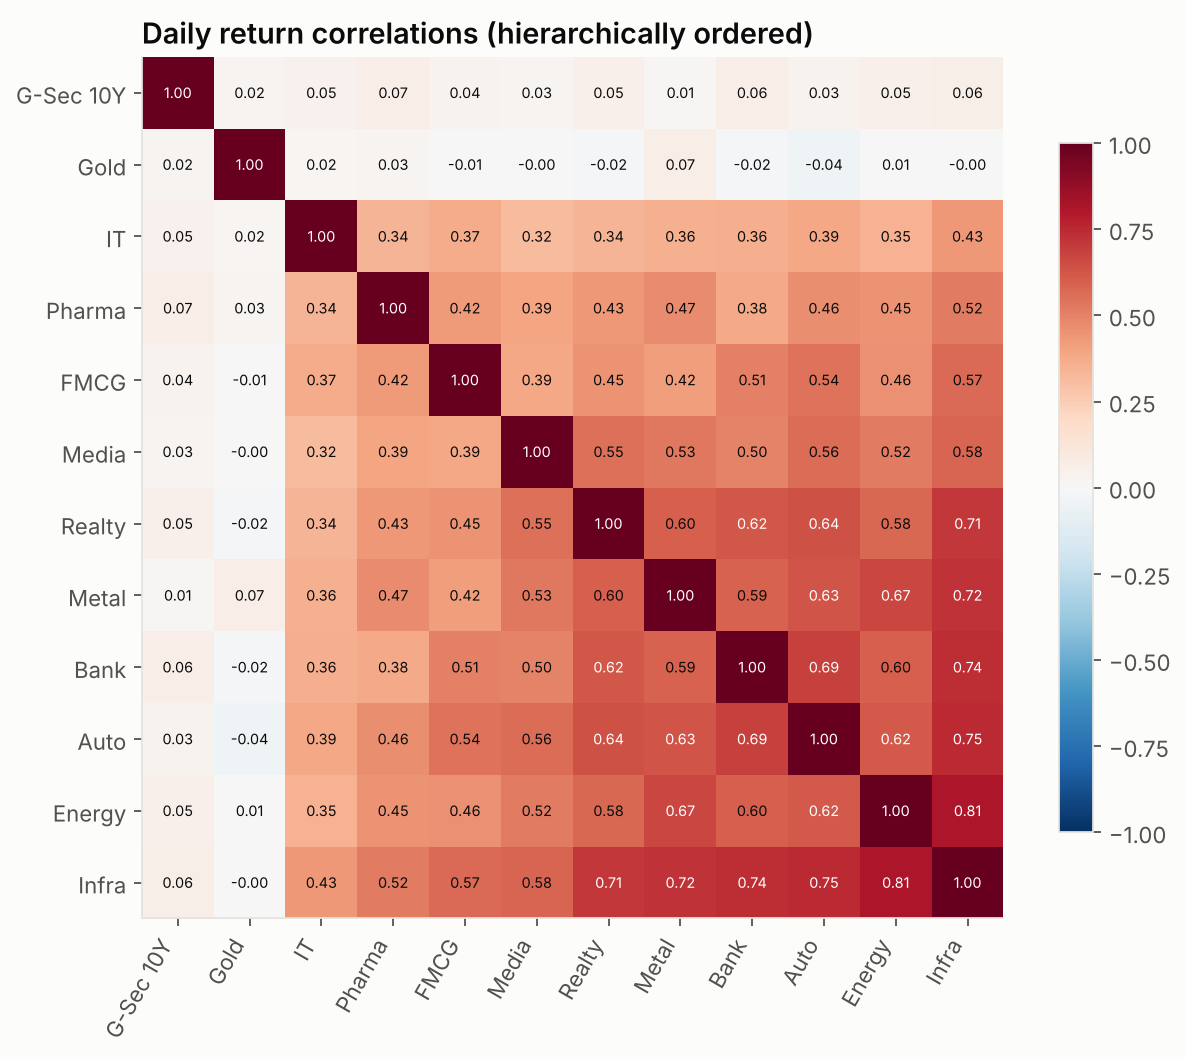

Average pairwise correlation among equity sectors: 0.52


In [2]:
corr = ret.corr()
order = leaves_list(linkage(squareform(np.sqrt(0.5 * (1 - corr)), checks=False), "single"))
c_ord = corr.iloc[order, order]
fig, ax = plt.subplots(figsize=(8, 6.6))
im = ax.imshow(c_ord, cmap="RdBu_r", vmin=-1, vmax=1); ax.grid(False)
ax.set_xticks(range(len(c_ord)), c_ord.columns, rotation=60, ha="right"); ax.set_yticks(range(len(c_ord)), c_ord.index)
for i in range(len(c_ord)):
    for j in range(len(c_ord)):
        ax.text(j, i, f"{c_ord.iloc[i, j]:.2f}", ha="center", va="center", fontsize=6.5,
                color="white" if abs(c_ord.iloc[i, j]) > 0.6 else "#0b0b0b")
fig.colorbar(im, ax=ax, shrink=0.8); ax.set_title("Daily return correlations (hierarchically ordered)")
save(fig, "05_correlation")
avg_eq_corr = corr.iloc[:10, :10].values[np.triu_indices(10, 1)].mean()
print(f"Average pairwise correlation among equity sectors: {avg_eq_corr:.2f}")

## 2 · The allocation methods

In [3]:
def cov_lw(r):
    return pd.DataFrame(LedoitWolf().fit(r).covariance_, index=r.columns, columns=r.columns) * 252


def w_equal(r):
    return pd.Series(1 / r.shape[1], index=r.columns)


def w_invvol(r):
    iv = 1 / r.std()
    return iv / iv.sum()


def _opt(obj, n, cons=()):
    res = minimize(obj, np.full(n, 1 / n), bounds=[(0, 1)] * n,
                   constraints=[{"type": "eq", "fun": lambda w: w.sum() - 1}, *cons], method="SLSQP",
                   options={"maxiter": 500, "ftol": 1e-12})
    return res.x


def w_minvar(r):
    S = cov_lw(r).values
    return pd.Series(_opt(lambda w: w @ S @ w, len(S)), index=r.columns)


def w_maxsharpe(r):
    S = cov_lw(r).values; mu = r.mean().values * 252
    return pd.Series(_opt(lambda w: -(w @ mu) / np.sqrt(w @ S @ w), len(S)), index=r.columns)


def w_erc(r):
    S = cov_lw(r).values; n = len(S)
    def obj(w):
        rc = w * (S @ w); return ((rc - rc.mean()) ** 2).sum() * 1e4
    return pd.Series(_opt(obj, n), index=r.columns)


def w_hrp(r):
    S = cov_lw(r); C = r.corr()
    dist = np.sqrt(0.5 * (1 - C)).values
    link = linkage(squareform(dist, checks=False), "single")
    sort_ix = list(C.index[leaves_list(link)])
    w = pd.Series(1.0, index=sort_ix)
    clusters = [sort_ix]
    while clusters:
        clusters = [c[j:k] for c in clusters for j, k in ((0, len(c) // 2), (len(c) // 2, len(c))) if len(c) > 1]
        for i in range(0, len(clusters), 2):
            c0, c1 = clusters[i], clusters[i + 1]
            def cvar(c):
                s = S.loc[c, c].values; ivp = 1 / np.diag(s); ivp /= ivp.sum(); return ivp @ s @ ivp
            v0, v1 = cvar(c0), cvar(c1)
            a = 1 - v0 / (v0 + v1)
            w[c0] *= a; w[c1] *= 1 - a
    return w.reindex(r.columns)


METHODS = {"Equal weight": w_equal, "Max Sharpe (Markowitz)": w_maxsharpe, "Minimum variance": w_minvar,
           "Inverse volatility": w_invvol, "Equal risk contribution": w_erc, "Hierarchical risk parity": w_hrp}

## 3 · Walk-forward backtest (monthly rebalance, 252-day estimation window)

In [4]:
rebal = ret.resample("ME").last().index
rebal = [d for d in rebal if ret.index.get_indexer([d], method="ffill")[0] >= LOOKBACK]
weights = {m: {} for m in METHODS}
for d in rebal:
    win = ret.loc[:d].tail(LOOKBACK)
    for m, f in METHODS.items():
        weights[m][d] = f(win)
weights = {m: pd.DataFrame(v).T for m, v in weights.items()}


def backtest(wm: pd.DataFrame) -> pd.Series:
    w = wm.reindex(ret.index, method="ffill").shift(1).dropna(how="all")
    r = (w * ret.loc[w.index]).sum(axis=1)
    turn = wm.diff().abs().sum(axis=1).reindex(w.index).shift(1).fillna(0)
    return r - turn * COST


port = {m: backtest(w) for m, w in weights.items()}
start = max(p.index[0] for p in port.values())
port = {m: p.loc[start:] for m, p in port.items()}
rf_s, nb = rf.loc[start:], nifty_r.loc[start:]
rows = [metrics.summary(nb, rf_s, name="NIFTY 50 (100% equity)")] + \
       [metrics.summary(p, rf_s, nb, name=m) for m, p in port.items()]
for row, (m, w) in zip(rows[1:], weights.items()):
    row["avg_turnover_monthly"] = float(w.diff().abs().sum(axis=1).mean() / 2)
    row["avg_max_weight"] = float(w.max(axis=1).mean())
perf = metrics.table(rows)
perf[["cagr", "vol", "sharpe", "sortino", "max_dd", "calmar", "beta", "avg_turnover_monthly"]]

,cagr,vol,sharpe,sortino,max_dd,calmar,beta,avg_turnover_monthly
name,,,,,,,,
NIFTY 50 (100% equity),11.3%,16.2%,0.41,0.56,-38.4%,0.29,nan,nan
Equal weight,12.4%,14.1%,0.52,0.70,-35.8%,0.35,0.80,0.00
Max Sharpe (Markowitz),10.4%,9.5%,0.53,0.72,-16.6%,0.62,0.31,0.16
Minimum variance,7.6%,4.4%,0.48,0.68,-7.7%,0.99,0.14,0.03
Inverse volatility,10.7%,9.7%,0.55,0.73,-25.0%,0.43,0.55,0.01
Equal risk contribution,11.0%,8.2%,0.67,0.91,-19.4%,0.57,0.44,0.02
Hierarchical risk parity,8.3%,5.3%,0.52,0.71,-12.4%,0.67,0.24,0.03


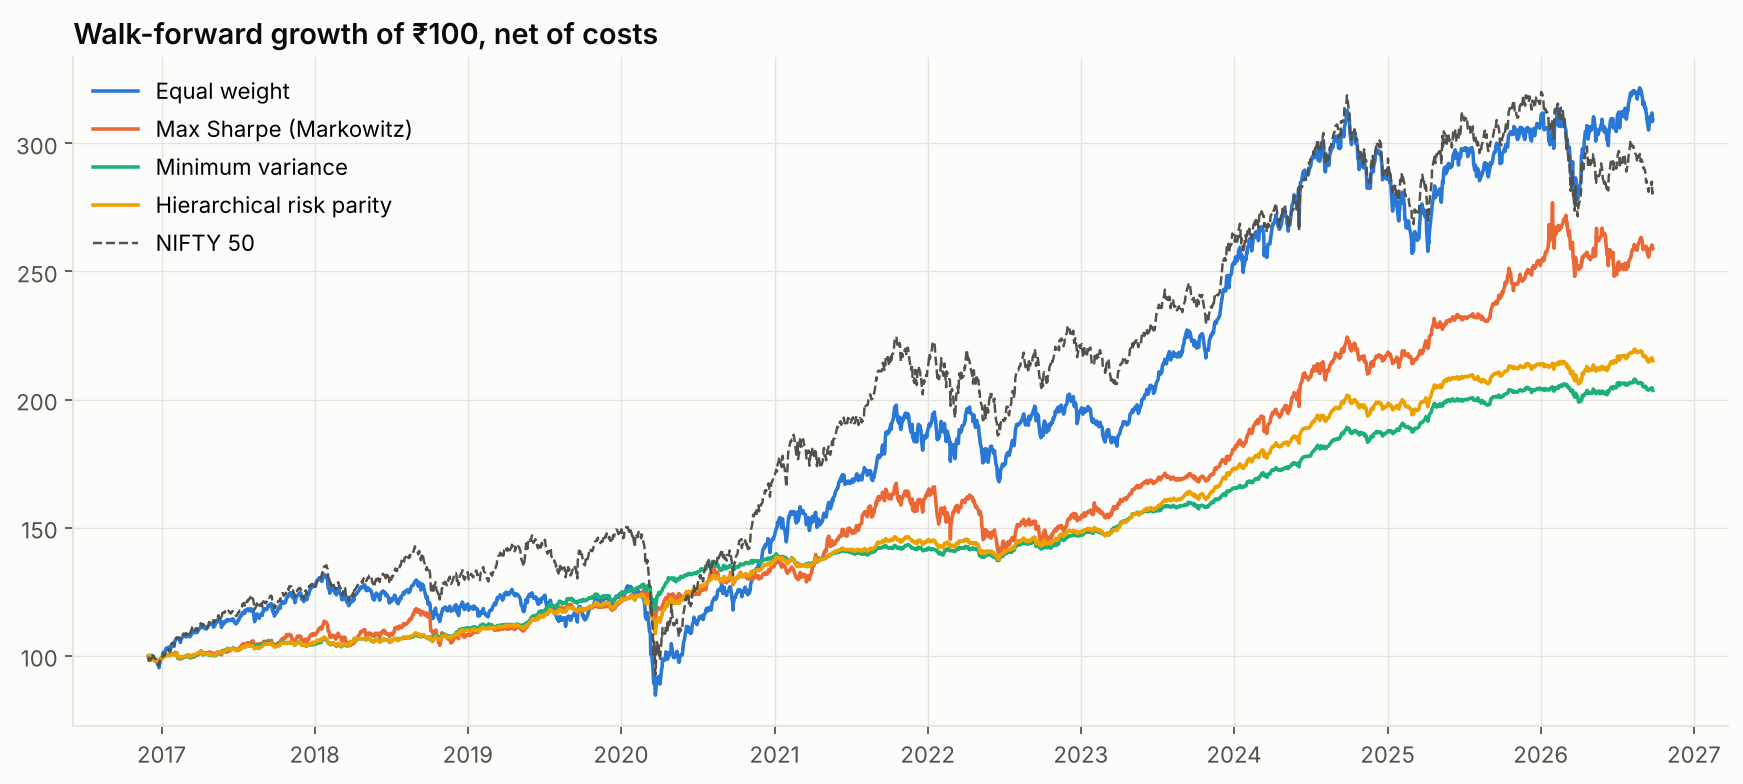

PosixPath('/home/claude/nse-quant-lab/reports/figures/05_walkforward.png')

In [5]:
fig, ax = plt.subplots(figsize=(11, 5))
show = ["Equal weight", "Max Sharpe (Markowitz)", "Minimum variance", "Hierarchical risk parity"]
for i, m in enumerate(show):
    ax.plot(port[m].index, (1 + port[m]).cumprod() * 100, color=PALETTE[i], label=m)
ax.plot(nb.index, (1 + nb).cumprod() * 100, color="#52514e", lw=1.1, ls="--", label="NIFTY 50")
ax.set_title("Walk-forward growth of ₹100, net of costs"); ax.legend()
save(fig, "05_walkforward")

## 4 · Stress tests — how each allocation behaved in real crises

In [6]:
episodes = {"COVID crash (Feb-Mar 2020)": ("2020-02-19", "2020-03-23"),
            "Rate-hike drawdown (Oct-21 to Jun-22)": ("2021-10-18", "2022-06-17"),
            "FPI sell-off (Sep-24 to Mar-25)": ("2024-09-26", "2025-03-04"),
            "2026 correction (Jan-Mar 2026)": ("2026-01-05", "2026-03-30")}
stress = pd.DataFrame({ep: {**{m: float((1 + p.loc[a:b]).prod() - 1) for m, p in port.items()},
                            "NIFTY 50": float((1 + nb.loc[a:b]).prod() - 1)} for ep, (a, b) in episodes.items()})
stress.style.format("{:.1%}") if False else stress.round(3)

,COVID crash (Feb-Mar 2020),Rate-hike drawdown (Oct-21 to Jun-22),FPI sell-off (Sep-24 to Mar-25),2026 correction (Jan-Mar 2026)
Equal weight,-0.313,-0.140,-0.170,-0.106
Max Sharpe (Markowitz),-0.074,-0.148,-0.034,-0.011
Minimum variance,-0.069,-0.042,-0.005,-0.013
Inverse volatility,-0.237,-0.097,-0.089,-0.071
Equal risk contribution,-0.186,-0.074,-0.088,-0.057
Hierarchical risk parity,-0.118,-0.060,-0.033,-0.029
NIFTY 50,-0.365,-0.166,-0.151,-0.152


## 5 · What the methods hold today — and where the risk really comes from

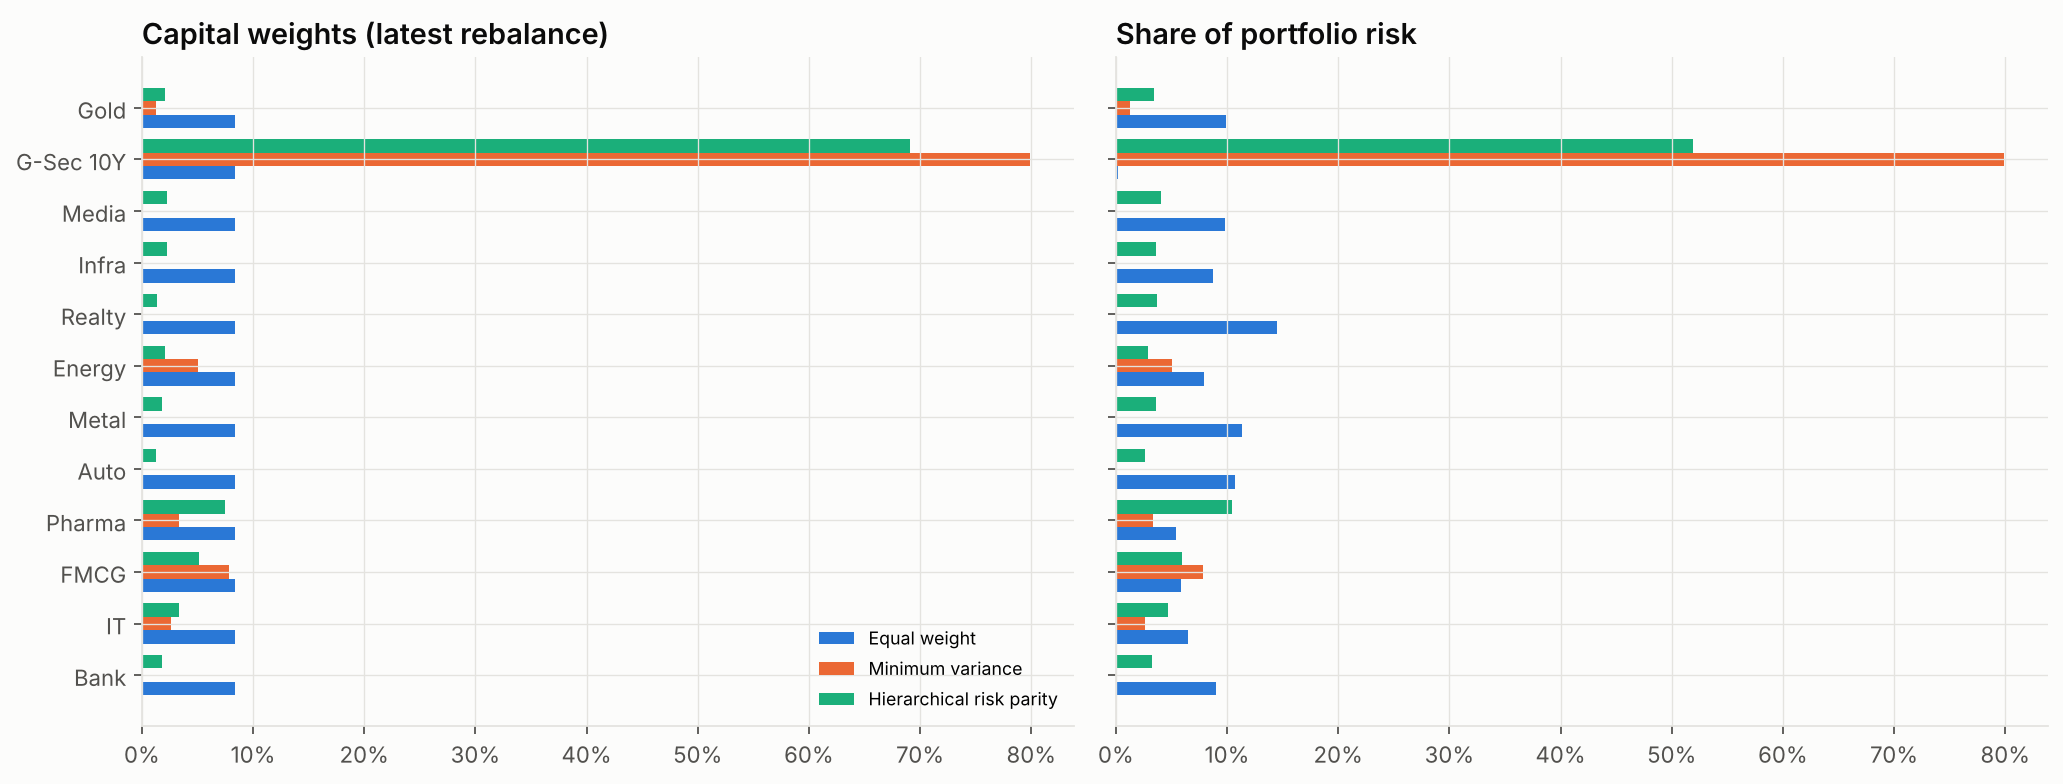

PosixPath('/home/claude/nse-quant-lab/reports/figures/05_weights_vs_risk.png')

In [7]:
last = {m: w.iloc[-1] for m, w in weights.items()}
cur = pd.DataFrame(last)
S_now = cov_lw(ret.tail(LOOKBACK))
rc = {}
for m, w in last.items():
    contrib = w * (S_now @ w); rc[m] = contrib / contrib.sum()
rc = pd.DataFrame(rc)

fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
ms = ["Equal weight", "Minimum variance", "Hierarchical risk parity"]
y = np.arange(len(cur)); h = 0.26
for i, m in enumerate(ms):
    axes[0].barh(y + (i - 1) * h, cur[m], h, color=PALETTE[i], label=m)
    axes[1].barh(y + (i - 1) * h, rc[m], h, color=PALETTE[i])
axes[0].set_yticks(y, cur.index); axes[0].set_title("Capital weights (latest rebalance)"); axes[0].legend(fontsize=8)
axes[1].set_title("Share of portfolio risk")
for a in axes:
    a.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
save(fig, "05_weights_vs_risk")

Equal *capital* is not equal *risk*: in the 1/N portfolio the ten equity sectors supply nearly all
of the volatility while bonds and gold are passengers. HRP and minimum variance push risk toward
a genuinely diversified mix.

## 6 · The efficient frontier (latest window) — and why the optimum is a mirage

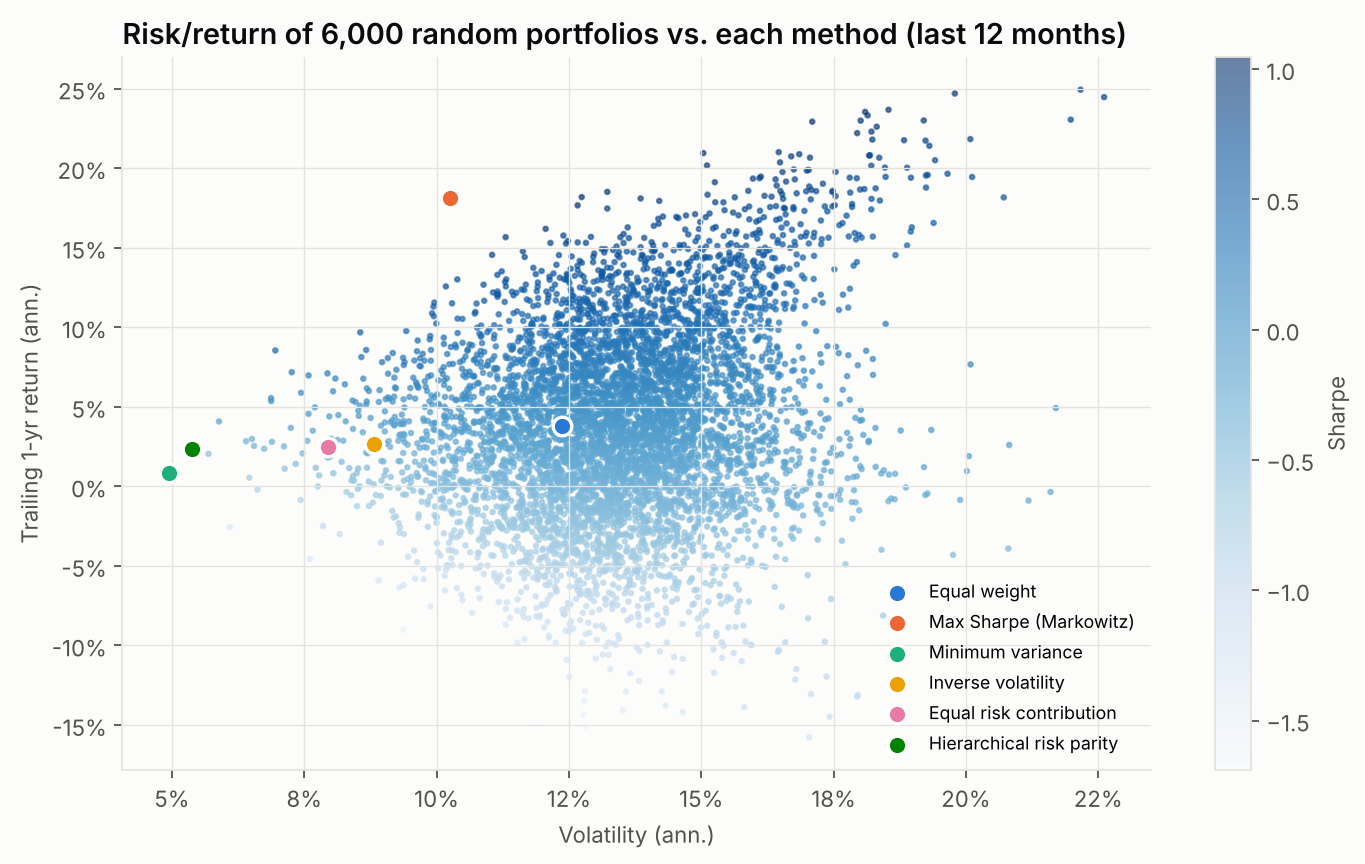

PosixPath('/home/claude/nse-quant-lab/reports/figures/05_frontier.png')

In [8]:
win = ret.tail(LOOKBACK); S = cov_lw(win).values; mu = win.mean().values * 252
rng = np.random.default_rng(1)
rand_w = rng.dirichlet(np.ones(len(mu)) * 0.6, 6000)
rv = np.sqrt(np.einsum("ij,jk,ik->i", rand_w, S, rand_w)); rr = rand_w @ mu
fig, ax = plt.subplots(figsize=(9, 5.5))
sc = ax.scatter(rv, rr, c=(rr - rf.tail(LOOKBACK).mean() * 252) / rv, cmap="Blues", s=4, alpha=0.6)
for i, (m, w) in enumerate(last.items()):
    wv = w.values
    ax.scatter(np.sqrt(wv @ S @ wv), wv @ mu, s=70, color=PALETTE[i], edgecolor="white", lw=1.5, zorder=5, label=m)
ax.set_xlabel("Volatility (ann.)"); ax.set_ylabel("Trailing 1-yr return (ann.)")
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
fig.colorbar(sc, ax=ax, label="Sharpe"); ax.legend(fontsize=8, loc="lower right")
ax.set_title("Risk/return of 6,000 random portfolios vs. each method (last 12 months)")
save(fig, "05_frontier")

## Takeaways

* **Diversifying across sectors alone barely helps** — equity sectors have ~0.52 average correlation;
  1/N across sectors + bonds + gold still fell 31% in the COVID crash.
* **Equal risk contribution had the best Sharpe (~0.67 vs 0.41 for NIFTY)** with ~11% CAGR at half the
  index's volatility and max drawdown of −19% vs −38%, using no return forecasts at all.
* **Markowitz max-Sharpe looks fine on the headline numbers but is fragile:** its latest weights put 42%
  in a single sector (Pharma) and it turns over ~16% of the book a month — 5-10× the risk-based
  methods. That is estimation error, not insight.
* **Minimum variance and HRP are the crisis performers** (−7% and −12% in the COVID crash vs −37% for
  NIFTY), but they are bond-heavy (70-80% G-Sec), so they suit a conservative mandate. HRP achieves this
  without any matrix inversion, which makes it the most robust choice when assets are many and data short.

In [9]:
data.save_results("05_portfolio", {
    "assets": list(ASSETS), "avg_equity_sector_corr": avg_eq_corr,
    "performance": rows, "stress": {ep: stress[ep].to_dict() for ep in stress.columns},
    "current_weights": {m: w.round(4).to_dict() for m, w in last.items()},
    "risk_contrib": {m: rc[m].round(4).to_dict() for m in rc.columns},
    "equity_curves": {m: {str(d.date()): x for d, x in ((1 + p).cumprod() * 100).resample("ME").last().round(2).items()}
                      for m, p in {**port, "NIFTY 50": nb}.items()},
    "as_of": str(ret.index[-1].date()),
})
print("saved")

saved
